In [1]:
import os
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 42
MATCH_WEIGHTS = {'age': 0.9, 'sex': 1.0, 'instrument': 0}
EXPORT_RESULTS = True
OUTPUT_DIR = Path(f'out/demographic_matching')


ieeg_dir = Path('/users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/ieeg_shortWOBS_fs250')
ieeg_subjects = [p.name.removesuffix('_epochs.p') for p in ieeg_dir.glob('*_epochs.p')]

ieeg_dem = pd.read_csv('/users/barbara/Desktop/MINDLAB2021_MEG-TempSeqAges/scratch/learning_bach_iEEG/misc/clean_dataset.csv')
meg_dem=pd.read_excel('/users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/MEG/SubjectsDataCollection_APR2020_TEMP.xlsx', 'Background questionnaire')

ieeg_dem_=ieeg_dem[['subject', 'age', 'sex', 'instrument']]
ieeg_dem_ = ieeg_dem_[ieeg_dem_['subject'].isin(ieeg_subjects)].reset_index(drop=True)
ieeg_dem_['instrument'] = ieeg_dem_['instrument'].fillna(False).apply(lambda x : 'Yes' if x != False else 'No')
ieeg_dem_=ieeg_dem_.dropna().reset_index(drop=True) # Remove DA037, LL13 (???)
meg_dem_ = meg_dem[['Subject', 'Age', 'Sex', '12. Are you a musician?']].dropna().reset_index(drop=True)
meg_dem_  =meg_dem_.rename(columns={'Subject' : 'subject', 'Age':'age', 'Sex':'sex', '12. Are you a musician?':'instrument'})


## Nearest-neighbor demographic matching

Greedy one-to-one matching without replacement: visit iEEG participants in a reproducibly shuffled order and select the nearest unused MEG participant. The original loading and iEEG instrument Yes/No conversion above are preserved, including the classification of missing instrument entries as No.

Age is standardized using the combined eligible cohorts' sample standard deviation $s_a$. Sex and instrument status are nominal categories. The mixed distance is
$$d(i,j)=\sqrt{w_a[(a_i-a_j)/s_a]^2+w_s\mathbf{1}(s_i\ne s_j)+w_m\mathbf{1}(m_i\ne m_j)}.$$
All three weights default to 1: one categorical mismatch contributes as much squared distance as an age difference of one standard deviation. Sex and instrument matches are preferred through penalties, but are **not required to be exact**. Review mismatch flags and age gaps. Weights encode substantive choices and should be specified before downstream outcome analysis.

Greedy matching depends on visit order and does not minimize total distance globally. The seed fixes the order for reproducibility; ties use MEG subject-ID order. Matching addresses observed demographic similarity only. Instrument playing and self-reported musician status still require substantive comparability.


In [2]:
def prepare_for_matching(frame):
    SEX_ALIASES = {'f': 'female', 'woman': 'female', 'm': 'male', 'man': 'male'}
    out = frame[['subject', 'age', 'sex', 'instrument']].copy()
    out['subject'] = out['subject'].astype('string').str.strip()
    if out['subject'].isna().any() or out['subject'].eq('').any() or out['subject'].duplicated().any():
        raise ValueError('Subject IDs must be nonmissing and unique within each cohort.')
    out['age'] = pd.to_numeric(out['age'], errors='raise')
    if not np.isfinite(out['age'].to_numpy(float)).all() or (out['age'] <= 0).any():
        raise ValueError('Ages must be finite and positive.')
    for col in ['sex', 'instrument']:
        out[col] = out[col].astype('string').str.strip().str.lower()
        if out[col].isna().any() or out[col].eq('').any():
            raise ValueError(f'Missing or empty {col} labels.')
    out['sex'] = out['sex'].replace(SEX_ALIASES)
    if not out['instrument'].isin(['yes', 'no']).all():
        raise ValueError('Instrument must contain Yes/No labels in both cohorts.')
    out['instrument'] = out['instrument'].map({'yes': 'Yes', 'no': 'No'})
    return out.sort_values('subject').reset_index(drop=True)

ieeg_eligible = prepare_for_matching(ieeg_dem_)
meg_eligible = prepare_for_matching(meg_dem_)
print(f'Eligible participants: {len(ieeg_eligible)} iEEG; {len(meg_eligible)} MEG')

Eligible participants: 28 iEEG; 78 MEG


In [3]:
def nearest_neighbor_match(ieeg, meg, weights=None, random_state=42):
    """Greedy nearest available neighbor on standardized age and category mismatches."""
    weights = {'age': 1.0, 'sex': 1.0, 'instrument': 1.0} if weights is None else weights
    w = np.asarray([weights[k] for k in ['age', 'sex', 'instrument']], dtype=float)
    age_scale = pd.concat([ieeg['age'], meg['age']], ignore_index=True).std(ddof=1)
    age_scale = float(age_scale) if age_scale > 0 else 1.0
    age_gap = np.abs(ieeg['age'].to_numpy(float)[:, None] - meg['age'].to_numpy(float)[None, :])

    squared = w[0] * (age_gap / age_scale)**2
    for weight, col in zip(w[1:], ['sex', 'instrument']):
        squared += weight * (ieeg[col].to_numpy()[:, None] != meg[col].to_numpy()[None, :])
    distances = np.sqrt(squared)
    visit_order = np.random.default_rng(random_state).permutation(len(ieeg))
    available = np.ones(len(meg), dtype=bool)
    selected = np.empty(len(ieeg), dtype=int)
    for i in visit_order:
        j = int(np.argmin(np.where(available, distances[i], np.inf)))
        selected[i] = j
        available[j] = False

    # Return pairs in input iEEG order, with the greedy visit order recorded.
    pairs = pd.concat([ieeg.reset_index(drop=True).add_prefix('ieeg_'),
                       meg.iloc[selected].reset_index(drop=True).add_prefix('meg_')], axis=1)
    visit_rank = np.empty(len(ieeg), dtype=int)
    visit_rank[visit_order] = np.arange(1, len(ieeg) + 1)
    pairs['matching_order'] = visit_rank
    pairs['distance'] = distances[np.arange(len(ieeg)), selected]
    pairs['age_gap_years'] = age_gap[np.arange(len(ieeg)), selected]
    pairs['meg_minus_ieeg_age'] = pairs['meg_age'] - pairs['ieeg_age']
    
    for col in ['sex', 'instrument']:
        pairs[f'{col}_match'] = pairs[f'ieeg_{col}'] == pairs[f'meg_{col}']
    
    assert pairs['meg_subject'].is_unique
    
    return pairs, age_scale


In [4]:
matched_pairs, age_scale = nearest_neighbor_match(ieeg_eligible, meg_eligible, weights=MATCH_WEIGHTS, random_state=RANDOM_STATE)
matched_meg_subjects = matched_pairs['meg_subject'].tolist()
meg_matched = meg_eligible.set_index('subject').loc[matched_meg_subjects].reset_index()
matched_pairs['meg_subject'] = matched_pairs['meg_subject'].apply(lambda x : str(int(float(x))))

In [5]:
# PPL STATS

from scipy.stats import ttest_ind
res = ttest_ind(matched_pairs.ieeg_age, matched_pairs.meg_age)
print('Age', res)

from scipy.stats import fisher_exact
pop1_counts = matched_pairs.ieeg_sex.value_counts()
pop2_counts = matched_pairs.meg_sex.value_counts()
table = [[pop1_counts.get('male', 0), pop1_counts.get('female', 0)],[pop2_counts.get('male', 0), pop2_counts.get('female', 0)]]
res = fisher_exact(table)
print('Sex', res)

pop1_counts = matched_pairs.ieeg_instrument.value_counts()
pop2_counts = matched_pairs.meg_instrument.value_counts()
table = [[pop1_counts.get('Yes', 0), pop1_counts.get('No', 0)],[pop2_counts.get('Yes', 0), pop2_counts.get('No', 0)]]
res = fisher_exact(table)
print('Musical expertise', res)

Age TtestResult(statistic=np.float64(0.32575926378845577), pvalue=np.float64(0.7458655037031534), df=np.float64(54.0))
Sex SignificanceResult(statistic=np.float64(0.8653846153846154), pvalue=1.0)
Musical expertise SignificanceResult(statistic=np.float64(4.5), pvalue=np.float64(0.015124290524863027))


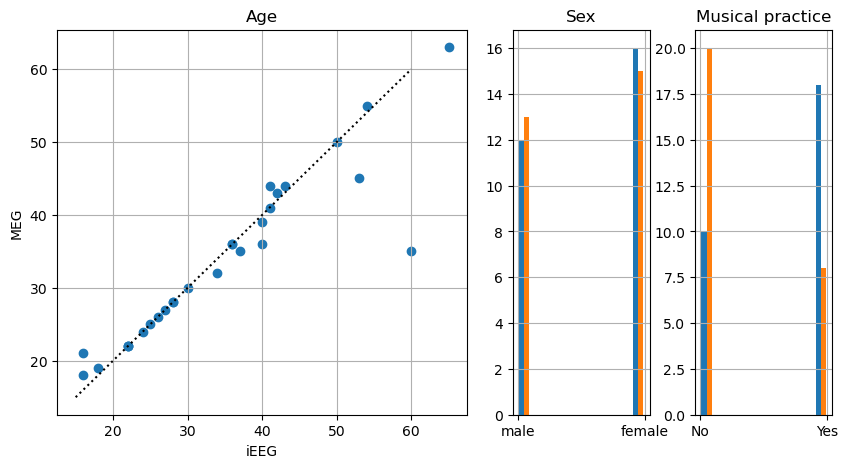

In [6]:
fig, ax=plt.subplots(1, 3, figsize=(10, 5), width_ratios=[3/5, 1/5, 1/5])

ax[0].scatter(matched_pairs.ieeg_age, matched_pairs.meg_age)
ax[0].plot([15, 60], [15, 60], ls=':', c='k')
ax[0].set_title('Age')
ax[0].set_xlabel('iEEG')
ax[0].set_ylabel('MEG')

ax[1].hist(matched_pairs[['ieeg_sex', 'meg_sex']])
ax[1].set_title('Sex')
ax[2].hist(matched_pairs[['ieeg_instrument', 'meg_instrument']])
ax[2].set_title('Musical practice')

for a in ax :
    a.grid(True)


## Balance and pair quality

Signed standardized mean differences (SMDs) compare MEG minus iEEG. The denominator is the pooled **unmatched** standard deviation and is held fixed after matching. Binary covariates use Bernoulli variances; multicategory sex is evaluated with one indicator per category. An absolute SMD of 0.1 is a descriptive reference, not a guarantee of adequate balance. Review raw age distributions and the largest pairwise gaps as well. Greedy nearest-neighbor matching does not guarantee categorical or age balance. Inspect both the cohort-level diagnostics and individual pair mismatches.


In [7]:
def balance_table(ieeg, meg, selected):
    features = {'Age (years)': (ieeg['age'], meg['age'], selected['age'])}
    for column in ['sex', 'instrument']:
        for level in sorted(set(ieeg[column]) | set(meg[column])):
            features[f'{column}: {level}'] = tuple((frame[column] == level).astype(float)
                                                    for frame in (ieeg, meg, selected))
    records = []
    for name, (target, before, after) in features.items():
        binary = name != 'Age (years)'
        var = lambda x: x.mean() * (1 - x.mean()) if binary else x.var(ddof=1)
        scale = np.sqrt((var(target) + var(before)) / 2)
        def smd(value):
            delta = value.mean() - target.mean()
            return delta / scale if scale > 0 else (0.0 if delta == 0 else np.nan)
        records.append({'covariate': name, 'iEEG_mean_or_proportion': target.mean(),
                        'MEG_before': before.mean(), 'MEG_matched': after.mean(),
                        'SMD_before': smd(before), 'SMD_matched': smd(after)})
    return pd.DataFrame(records).set_index('covariate')



In [8]:
balance = balance_table(ieeg_eligible, meg_eligible, meg_matched)
balance.round(3)

,iEEG_mean_or_proportion,MEG_before,MEG_matched,SMD_before,SMD_matched
covariate,,,,,
Age (years),34.857,28.718,33.786,-0.559,-0.097
sex: female,0.571,0.615,0.536,0.090,-0.073
sex: male,0.429,0.385,0.464,-0.090,0.073
instrument: No,0.357,0.718,0.714,0.776,0.768
instrument: Yes,0.643,0.282,0.286,-0.776,-0.768


In [9]:
path = '/projects/MINDLAB2020_MEG-AuditoryPatternRecognition/scratch/leonardo/after_maxfilter_v2/Source_LBPD/Block_3/Beam_abs_0_sens_1_freq_broadband_invers_5'
file_list = sorted([file for file in os.listdir(path) if file[:4] == 'SUBJ'])

for i, subj_meg in enumerate(matched_pairs.meg_subject) : 
    while len(subj_meg) < 4 :
        subj_meg = '0' + subj_meg
    if not os.path.isfile(path + f'/SUBJ_{subj_meg}_norm0_abs_0.mat') : 
        print(subj_meg)
    else :
        matched_pairs.loc[i, 'path_to_meg'] = path + f'/SUBJ_{subj_meg}_norm0_abs_0.mat'
    

In [10]:
# Optional reproducible outputs; matching code remains entirely in this notebook.
if EXPORT_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    matched_pairs.to_csv(OUTPUT_DIR / 'matched_pairs.csv', index=False)
    balance.to_csv(OUTPUT_DIR / 'balance.csv')
    meg_matched.to_csv(OUTPUT_DIR / 'selected_meg_demographics.csv', index=False)
    pd.Series(matched_meg_subjects, name='subject').to_csv(OUTPUT_DIR / 'selected_meg_subjects.csv', index=False)
    print(f'Saved results to {OUTPUT_DIR.resolve()}')


Saved results to /users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/out/demographic_matching
